# Laboratorio 9: Computación cuántica, oscilaciones de Rabi y estados de Bell

**Andrés Felipe Serrano Barrios**

Física Computacional I (0302151), grupo 001

Instituto de Física, Universidad de Antioquia

Semestre 2026-2, profesor Andrés Felipe Rivera Romero

In [1]:
import json
import time
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from qiskit import QuantumCircuit, qasm2, transpile
from qiskit.quantum_info import Operator
from qiskit.visualization import plot_histogram
from qiskit_aer import Aer, AerSimulator

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

---

# 1. Oscilaciones de Rabi en la molécula de amoníaco (NH₃)

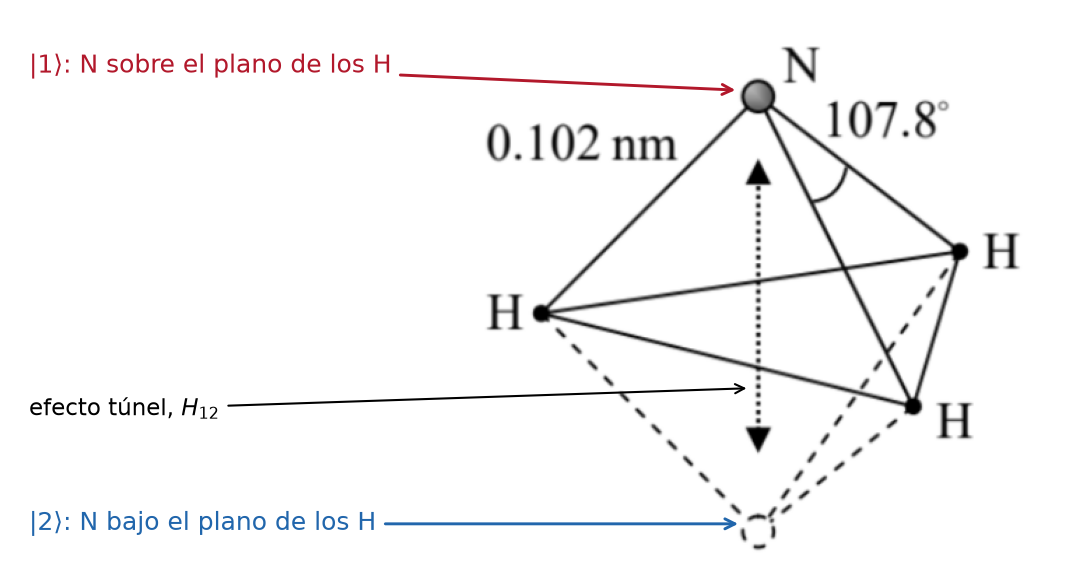

En la figura de la [sesión](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Sesiones/QC/3_two_level_system.ipynb) (con los rótulos agregados), $\ket{1}$ es el nitrógeno sobre
el plano de los hidrógenos y $\ket{2}$ el nitrógeno debajo, en el círculo punteado. La molécula pasa de una posición a la
otra por efecto túnel (flecha punteada), y ese acoplamiento es el término $H_{12}$ del hamiltoniano. Se usa la notación
de la [sesión de sistemas de dos niveles](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Sesiones/QC/3_two_level_system.ipynb):

$$H=\begin{pmatrix}H_{11}&H_{12}\\H_{12}^*&H_{22}\end{pmatrix}=\alpha\,\sigma_0+\vec c\cdot\vec\sigma,\qquad
\Omega_R=\frac{|H_{12}|}{\hbar},\qquad\Delta=\frac{c_z}{\hbar}=\frac{H_{11}-H_{22}}{2\hbar},\qquad
\Omega=\frac{|\vec c|}{\hbar}=\sqrt{\Omega_R^2+\Delta^2}.$$

**Paso 1. Frecuencia de Rabi a partir del desdoblamiento.** Sin campo externo las dos posiciones del nitrógeno son
simétricas, $H_{11}=H_{22}$, así que $c_z=0$ y $\Delta=0$. El desdoblamiento de la sesión queda

$$\Delta E=2|\vec c|=\sqrt{(H_{11}-H_{22})^2+4|H_{12}|^2}=2|H_{12}|=2\hbar\Omega_R.$$

El valor $\Omega/2\pi\approx24{,}79$ GHz del enunciado viene del texto de [Likharev](https://phys.libretexts.org/Bookshelves/Quantum_Mechanics/Essential_Graduate_Physics_-_Quantum_Mechanics_(Likharev)/05%3A_Some_Exactly_Solvable_Problems/5.01%3A_Two-level_Systems), donde
$\Omega\equiv\Delta E/\hbar$. En la notación de la sesión $\Omega=|\vec c|/\hbar=\Delta E/2\hbar$, de modo que el dato se
lee como $\Delta E=hf_0$ con $f_0=24{,}79$ GHz:

$$\Omega_R=\frac{\Delta E}{2\hbar}=\frac{2\pi\hbar f_0}{2\hbar}=\pi f_0,\qquad
f_R=\frac{\Omega_R}{2\pi}=\frac{f_0}{2}=12{,}395\ \text{GHz}.$$

**Paso 2. Frecuencia generalizada con $\Delta=\Omega_R/2$.** La desintonía (*detuning*) corresponde a $H_{11}\neq H_{22}$,
como la que produce un campo eléctrico a lo largo del eje de la molécula
([Feynman, vol. III, cap. 9](https://www.feynmanlectures.caltech.edu/III_09.html)); el acoplamiento por efecto túnel
$H_{12}$ no cambia, y $\Omega_R$ tampoco. Con $\Delta=\Omega_R/2$,

$$\Omega=\sqrt{\Omega_R^2+\frac{\Omega_R^2}{4}}=\frac{\sqrt5}{2}\,\Omega_R,\qquad
\frac{\Omega_R^2}{\Omega^2}=\frac{4}{5},\qquad\frac{\Delta^2}{\Omega^2}=\frac{1}{5},\qquad
\frac{\Omega}{2\pi}=\frac{\sqrt5}{2}\cdot12{,}395\ \text{GHz}=13{,}858\ \text{GHz}.$$

**Paso 3. Evolución desde $\ket{2}$.** Sin la fase global $e^{-i\alpha t/\hbar}$, el operador de evolución de la sesión es

$$U(t)=\cos(\Omega t)\,\sigma_0-i\sin(\Omega t)\,\frac{\vec c\cdot\vec\sigma}{|\vec c|},\qquad
\frac{\vec c\cdot\vec\sigma}{|\vec c|}=\frac{1}{|\vec c|}\begin{pmatrix}c_z&c_x-ic_y\\c_x+ic_y&-c_z\end{pmatrix}.$$

Con $c(0)=\begin{pmatrix}0\\1\end{pmatrix}$ se obtiene $c(t)=U(t)c(0)=\begin{pmatrix}U_{12}(t)\\U_{22}(t)\end{pmatrix}$, es decir,

$$c_1(t)=-i\sin(\Omega t)\,\frac{c_x-ic_y}{|\vec c|},\qquad c_2(t)=\cos(\Omega t)+i\sin(\Omega t)\,\frac{c_z}{|\vec c|}.$$

**Paso 4. Probabilidades.** Como $|c_x-ic_y|/|\vec c|=\Omega_R/\Omega$ y $c_z/|\vec c|=\Delta/\Omega$,

$$P_1(t)=|c_1(t)|^2=\frac{\Omega_R^2}{\Omega^2}\sin^2(\Omega t)=\frac45\sin^2(\Omega t),$$

$$P_2(t)=|c_2(t)|^2=\cos^2(\Omega t)+\frac{\Delta^2}{\Omega^2}\sin^2(\Omega t)=1-\frac45\sin^2(\Omega t).$$

$P_1+P_2=1$ y $P_2(0)=1$. Como $\sin^2(\Omega t)$ se repite cada $\pi/\Omega$, las probabilidades oscilan con periodo
$T=\pi/\Omega$ y frecuencia $2\Omega/2\pi$.

In [2]:
hbar = 1.054571817e-34
h = 2*np.pi*hbar
f_0 = 24.79e9
delta_E = h*f_0


def omega_rabi(cx, cy):
    return np.sqrt(cx**2 + cy**2)/hbar


def delta(cz):
    return np.abs(cz)/hbar


def omega(cx, cy, cz):
    return np.sqrt(omega_rabi(cx, cy)**2 + delta(cz)**2)


def P2(cx, cy, cz, t):
    return np.cos(omega(cx, cy, cz)*t)**2 + np.sin(omega(cx, cy, cz)*t)**2*(delta(cz)/omega(cx, cy, cz))**2


cx = delta_E/2
cy = 0.0
cz = hbar*omega_rabi(cx, cy)/2

print(f"Frecuencia de Rabi:       Omega_R = {omega_rabi(cx, cy):.4e} rad/s   f_R = Omega_R/2pi = {omega_rabi(cx, cy)/(2*np.pi):.4e} Hz")
print(f"Desintonía:               Delta   = {delta(cz):.4e} rad/s   Delta/2pi = {delta(cz)/(2*np.pi):.4e} Hz")
print(f"Frecuencia generalizada:  Omega   = {omega(cx, cy, cz):.4e} rad/s   Omega/2pi = {omega(cx, cy, cz)/(2*np.pi):.4e} Hz")
print(f"Periodo de las probabilidades: T = pi/Omega = {np.pi/omega(cx, cy, cz)*1e12:.2f} ps")

Frecuencia de Rabi:       Omega_R = 7.7880e+10 rad/s   f_R = Omega_R/2pi = 1.2395e+10 Hz
Desintonía:               Delta   = 3.8940e+10 rad/s   Delta/2pi = 6.1975e+09 Hz
Frecuencia generalizada:  Omega   = 8.7073e+10 rad/s   Omega/2pi = 1.3858e+10 Hz
Periodo de las probabilidades: T = pi/Omega = 36.08 ps


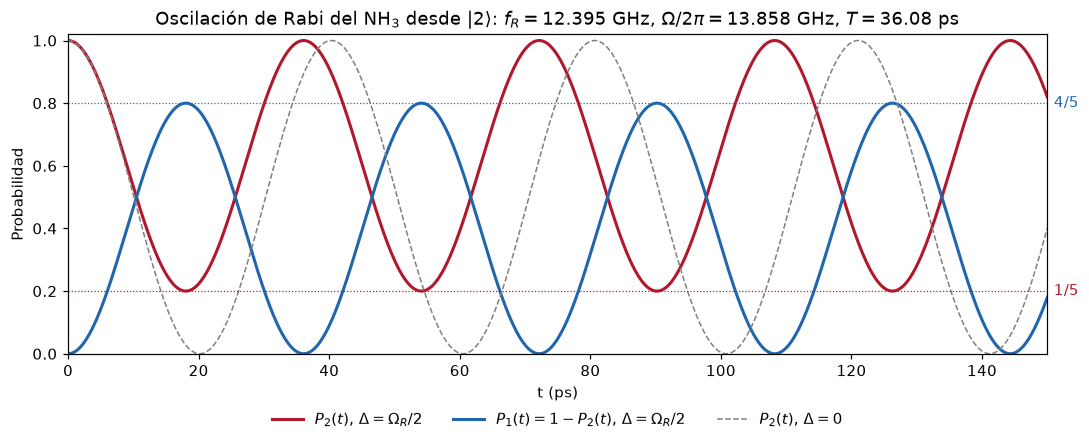

In [3]:
t = np.linspace(0, 150e-12, 1500)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(t*1e12, P2(cx, cy, cz, t), color="#b2182b", lw=2, label=r"$P_2(t)$, $\Delta=\Omega_R/2$")
ax.plot(t*1e12, 1 - P2(cx, cy, cz, t), color="#2166ac", lw=2, label=r"$P_1(t)=1-P_2(t)$, $\Delta=\Omega_R/2$")
ax.plot(t*1e12, P2(cx, cy, 0.0, t), color="gray", lw=1, ls="--", label=r"$P_2(t)$, $\Delta=0$")
ax.axhline(1/5, color="#b2182b", lw=0.8, ls=":")
ax.text(151, 1/5, "1/5", va="center", color="#b2182b")
ax.axhline(4/5, color="#2166ac", lw=0.8, ls=":")
ax.text(151, 4/5, "4/5", va="center", color="#2166ac")
ax.set_xlim(0, 150)
ax.set_ylim(0, 1.02)
ax.set_xlabel("t (ps)")
ax.set_ylabel("Probabilidad")
ax.set_title(f"Oscilación de Rabi del $\\mathrm{{NH_3}}$ desde $|2\\rangle$: $f_R={omega_rabi(cx, cy)/(2*np.pi)*1e-9:.3f}$ GHz, "
             f"$\\Omega/2\\pi={omega(cx, cy, cz)/(2*np.pi)*1e-9:.3f}$ GHz, $T={np.pi/omega(cx, cy, cz)*1e12:.2f}$ ps")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

La oscilación arranca en $P_2=1$ porque la molécula empieza en $\ket{2}$. Sin desintonía (curva gris) las probabilidades
oscilan con frecuencia $2\Omega_R/2\pi=f_0=24{,}79$ GHz, que es $\Delta E/h$, la frecuencia del enunciado. Con
$\Delta=\Omega_R/2$ la oscilación se acelera a $2\Omega/2\pi=27{,}72$ GHz (periodo de $36{,}08$ ps) y $P_2$ no baja de
$1/5$: la molécula nunca pasa por completo a $\ket{1}$.

---

# 2. Estado de Bell y entrelazamiento de tres qubits

Los circuitos se arman como en la [sesión de Qiskit](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Sesiones/QC/5_qiskit.ipynb): `QuantumCircuit`, `transpile` y el
simulador `qasm_simulator` de Aer, con 1000 disparos. La semilla `seed_simulator` fija los números aleatorios del
simulador, de modo que los conteos se repiten al volver a correr el cuaderno. Las compuertas $H$, $X$ y CX y su acción
sobre $\ket0$ y $\ket1$ son las de la [sesión de compuertas cuánticas](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Sesiones/QC/4_logic_gates_in_QC.ipynb).

Qiskit escribe los bits con el qubit 0 a la derecha: el resultado `01` de dos qubits significa $q_1=0$, $q_0=1$. Los kets
de abajo siguen el mismo orden, $\ket{q_1q_0}$ y $\ket{q_2q_1q_0}$.

## 2.1 Estado de Bell

**Paso 1.** Los qubits empiezan en $\ket{00}$. La Hadamard sobre $q_0$ da $H\ket0=(\ket0+\ket1)/\sqrt2$:

$$\ket{\psi_1}=\frac{\ket{00}+\ket{01}}{\sqrt2}.$$

**Paso 2.** La CX con control $q_0$ y blanco $q_1$ invierte $q_1$ solo cuando $q_0=1$, es decir, $\ket{01}\to\ket{11}$:

$$\ket{\psi_2}=\frac{\ket{00}+\ket{11}}{\sqrt2}=\ket{\Phi^+}.$$

**Paso 3.** Por la regla de Born, $P(00)=P(11)=\left|1/\sqrt2\right|^2=1/2$ y $P(01)=P(10)=0$.

**Paso 4.** $\ket{\Phi^+}$ está entrelazado: si fuera un producto $(a\ket0+b\ket1)\otimes(c\ket0+d\ket1)$, se necesitaría
$ac=bd=1/\sqrt2$ y $ad=bc=0$. Pero $ad=0$ obliga a $a=0$ o $d=0$, y cualquiera de los dos anula $ac$ o $bd$.

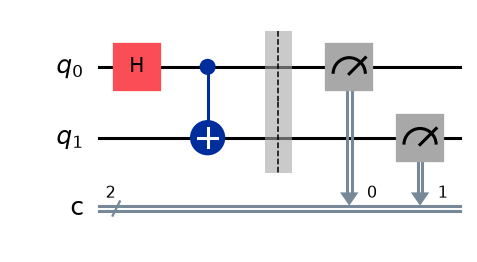

In [4]:
backend = Aer.get_backend("qasm_simulator")
disparos = 1000


def medir(circuito, semilla):
    compilado = transpile(circuito, backend)
    return backend.run(compilado, shots=disparos, seed_simulator=semilla).result().get_counts()


bell = QuantumCircuit(2, 2)
bell.h(0)
bell.cx(0, 1)
bell.barrier()
bell.measure([0, 1], [0, 1])
bell.draw(output="mpl", plot_barriers=True)

## 2.2 Tres qubits entrelazados

**Paso 1.** Con un tercer qubit, la Hadamard y la primera CX dan $(\ket{000}+\ket{011})/\sqrt2$, como en 2.1.

**Paso 2.** La CX con control $q_1$ y blanco $q_2$ invierte $q_2$ cuando $q_1=1$, $\ket{011}\to\ket{111}$:

$$\ket{\mathrm{GHZ}}=\frac{\ket{000}+\ket{111}}{\sqrt2},\qquad P(000)=P(111)=\frac12.$$

Los tres bits salen siempre iguales, aunque cada uno por separado es 0 o 1 con probabilidad $1/2$.

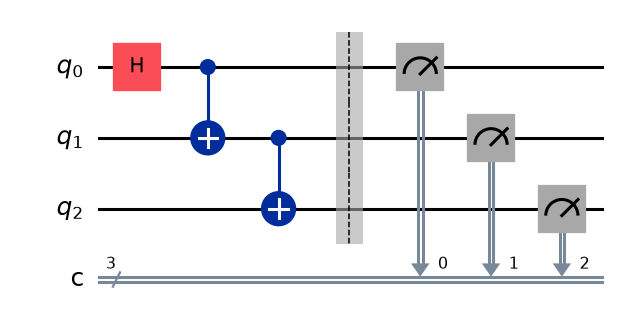

In [5]:
ghz = QuantumCircuit(3, 3)
ghz.h(0)
ghz.cx(0, 1)
ghz.cx(1, 2)
ghz.barrier()
ghz.measure([0, 1, 2], [0, 1, 2])
ghz.draw(output="mpl", plot_barriers=True)

## 2.3 Compuerta X sobre el qubit 1

**Paso 1.** $X\ket0=\ket1$ y $X\ket1=\ket0$ sobre $q_1$ cambian $\ket{000}\to\ket{010}$ y $\ket{111}\to\ket{101}$:

$$X_1\ket{\mathrm{GHZ}}=\frac{\ket{010}+\ket{101}}{\sqrt2},\qquad P(010)=P(101)=\frac12.$$

La correlación se conserva ($q_0=q_2\neq q_1$) y solo cambian los valores medidos. La $X$ va al final de las compuertas y
antes de `measure`: si se agrega después de la medida, los bits clásicos ya quedaron escritos y los conteos siguen en
`000` y `111`, como muestra la última línea de la celda de resultados.

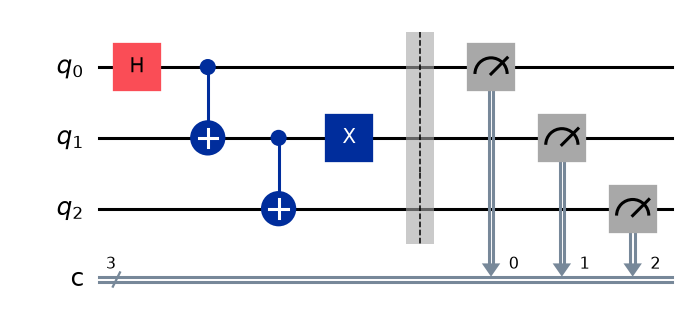

In [6]:
ghz_x = QuantumCircuit(3, 3)
ghz_x.h(0)
ghz_x.cx(0, 1)
ghz_x.cx(1, 2)
ghz_x.x(1)
ghz_x.barrier()
ghz_x.measure([0, 1, 2], [0, 1, 2])

ghz_x_despues = ghz.copy()
ghz_x_despues.x(1)

ghz_x.draw(output="mpl", plot_barriers=True)

## 2.4 Resultados en el simulador

Bell        00: 504 (+0.3 sigma), 11: 496 (-0.3 sigma)
GHZ         000: 472 (-1.8 sigma), 111: 528 (+1.8 sigma)
GHZ + X(1)  010: 527 (+1.7 sigma), 101: 473 (-1.7 sigma)

X(1) después de measure: {'000': 495, '111': 505}


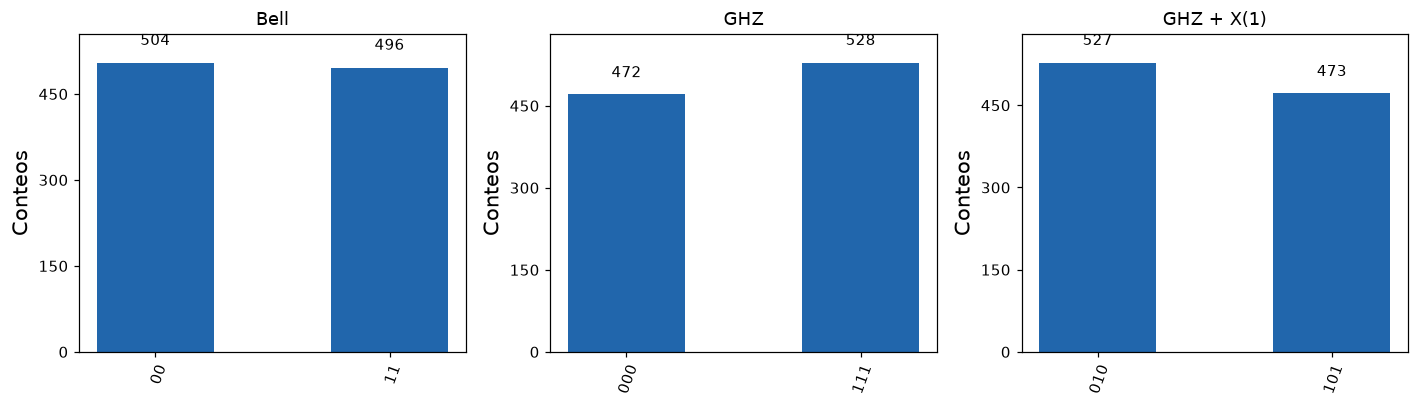

In [7]:
circuitos = {"Bell": bell, "GHZ": ghz, "GHZ + X(1)": ghz_x}
conteos = {}
semilla = 2026
for nombre, circuito in circuitos.items():
    conteos[nombre] = medir(circuito, semilla)
    semilla = semilla + 1

sigma = np.sqrt(disparos*0.5*0.5)
for nombre, resultado in conteos.items():
    texto = ", ".join(f"{clave}: {valor} ({(valor - disparos/2)/sigma:+.1f} sigma)" for clave, valor in sorted(resultado.items()))
    print(f"{nombre:<11} {texto}")
print(f"\nX(1) después de measure: {dict(sorted(medir(ghz_x_despues, semilla).items()))}")

fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8))
for eje, (nombre, resultado) in zip(ejes, conteos.items()):
    plot_histogram(resultado, ax=eje, bar_labels=True, color="#2166ac")
    eje.grid(False)
    eje.set_ylabel("Conteos")
    eje.set_title(nombre)
plt.tight_layout()
plt.show()

Solo aparecen los dos resultados que predice cada estado, y cada uno se queda cerca de la mitad de los disparos. La
diferencia con 500 se mide en desviaciones estándar de la binomial,

$$\sigma=\sqrt{Np(1-p)}=\sqrt{1000\cdot\tfrac12\cdot\tfrac12}\approx15{,}8,$$

y con las semillas del cuaderno queda por debajo de $2\sigma$ en los tres circuitos, que es lo esperable por azar.

---

# 3. Extra: equipo cuántico real de IBM

El simulador de la sección 2 calcula lo que daría un computador cuántico perfecto. Este extra corre los mismos circuitos
en un computador cuántico real de IBM para ver tres cosas que el simulador no puede mostrar:

1. **Entrelazamiento real.** Si dos qubits físicos quedan de verdad entrelazados (sección 3.2).
2. **Ruido.** Cuántos resultados equivocados da el equipo (sección 3.3).
3. **Compuertas del equipo.** Cómo se traducen los circuitos a las compuertas que el procesador sabe hacer (sección 3.1).

Se enviaron siete circuitos, los tres del punto 2 y los cuatro de la prueba de la sección 3.2, en un solo trabajo y con
1000 disparos cada uno. Se usó el plan gratuito de IBM, que da 10 minutos de equipo cada 28 días
([planes de IBM](https://quantum.cloud.ibm.com/docs/guides/plans-overview)). El envío lo hace el script
[`Lab_9_equipo_real_ibm.py`](https://github.com/AndresFSerrano/Fisica_Computacional_1/blob/main/Estudiantes/Serrano_4632/Lab_9_equipo_real_ibm.py) de esta carpeta, que también simula los
circuitos con el ruido que IBM reporta para ese equipo y guarda todo en `Lab_9_equipo_real_ibm.json`. El cuaderno lee ese
archivo, así que corre sin cuenta de IBM.

Qiskit escoge los qubits del chip que tienen menos error. En una prueba previa con un equipo simulado, los circuitos
quedaban en los dos primeros qubits del chip, uno de ellos con 17 % de error de lectura, y la prueba de entrelazamiento
fallaba.

## 3.1 Circuitos compilados para el equipo

El procesador no sabe hacer $H$ ni CX: solo hace $R_Z(\theta)$, $\sqrt X$, $X$ y CZ. Antes del envío, Qiskit traduce
cada circuito a esas compuertas y lo pone en qubits concretos del chip.

**Paso 1. Hadamard.** Salvo una fase global, $H=R_Z(\pi/2)\,\sqrt X\,R_Z(\pi/2)$.

**Paso 2. CX.** La CZ cambia el signo de $\ket{11}$ y deja igual los demás estados de la base. Como $HZH=X$
([sesión de compuertas](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Sesiones/QC/4_logic_gates_in_QC.ipynb)), una $H$ antes y otra después sobre el blanco convierten ese
cambio de signo en una inversión del blanco:

$$\mathrm{CX}_{0\to1}=H_1\,\mathrm{CZ}\,H_1.$$

**Paso 3. Simplificación.** Las rotaciones $R_Z$ seguidas sobre un mismo qubit se suman en una sola, por eso el circuito
traducido queda más corto que el reemplazo una por una.

La celda dibuja los circuitos tal como corrieron en el chip y comprueba, con la matriz de cada uno, que hacen lo mismo que
los del punto 2.

Equipo: ibm_marrakesh (156 qubits), plan open
Trabajo: dbt8753eq3sc73evga6g, 2026-11-16 04:23 UTC, 1000 disparos por circuito

Bell        q0, q1, ... -> qubits físicos [55, 54]   compuertas {'rz': 5, 'sx': 3, 'measure': 2, 'cz': 1, 'barrier': 1}
            mismo operador que el circuito del punto 2: True
GHZ         q0, q1, ... -> qubits físicos [53, 54, 55]   compuertas {'rz': 8, 'sx': 5, 'measure': 3, 'cz': 2, 'barrier': 1}
            mismo operador que el circuito del punto 2: True
GHZ + X(1)  q0, q1, ... -> qubits físicos [53, 54, 55]   compuertas {'rz': 8, 'sx': 5, 'measure': 3, 'cz': 2, 'x': 1, 'barrier': 1}
            mismo operador que el circuito del punto 2: True


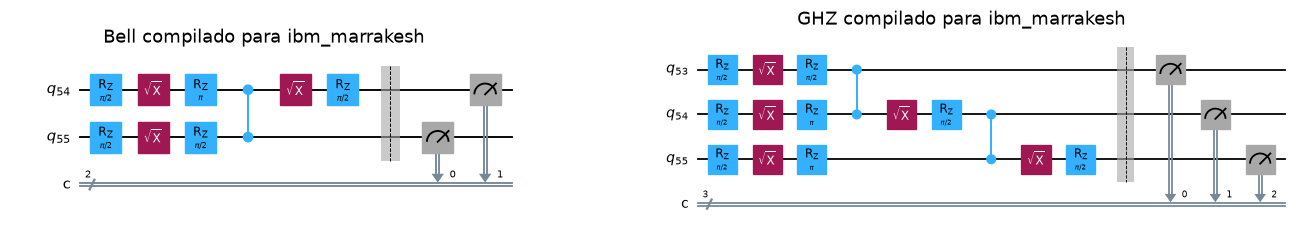

In [8]:
url_ibm = "https://raw.githubusercontent.com/AndresFSerrano/Fisica_Computacional_1/main/Estudiantes/Serrano_4632/Lab_9_equipo_real_ibm.json"
with urlopen(url_ibm) as respuesta:
    ibm = json.load(respuesta)

print(f"Equipo: {ibm['equipo']} ({ibm['qubits_equipo']} qubits), plan {ibm['plan']}")
print(f"Trabajo: {ibm['trabajo']}, {ibm['fecha_utc']} UTC, {ibm['disparos']} disparos por circuito\n")


def reducir(circuito, fisicos):
    reducido = QuantumCircuit(len(fisicos))
    for instruccion in circuito.data:
        if instruccion.operation.name in ("measure", "barrier"):
            continue
        indices = [fisicos.index(circuito.find_bit(q).index) for q in instruccion.qubits]
        reducido.append(instruccion.operation, indices)
    return reducido


compilados = {}
for nombre, ideal in [("Bell", bell), ("GHZ", ghz), ("GHZ + X(1)", ghz_x)]:
    compilados[nombre] = qasm2.loads(ibm["circuitos_equipo"][nombre], custom_instructions=qasm2.LEGACY_CUSTOM_INSTRUCTIONS)
    fisicos = ibm["qubits_fisicos"][nombre]
    igual = Operator(reducir(compilados[nombre], fisicos)).equiv(Operator(ideal.remove_final_measurements(inplace=False)))
    print(f"{nombre:<11} q0, q1, ... -> qubits físicos {fisicos}   compuertas {dict(compilados[nombre].count_ops())}")
    print(f"{'':<11} mismo operador que el circuito del punto 2: {igual}")

fig, ejes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
for eje, nombre in zip(ejes, ["Bell", "GHZ"]):
    compilados[nombre].draw(output="mpl", idle_wires=False, plot_barriers=True, ax=eje)
    eje.set_title(f"{nombre} compilado para {ibm['equipo']}")
plt.show()

## 3.2 Prueba de entrelazamiento (CHSH)

Que solo salgan `00` y `11` no basta para hablar de entrelazamiento: dos monedas que siempre caen igual darían el mismo
histograma. La prueba CHSH mide los qubits en varias direcciones y junta las correlaciones en un número $S$. Cualquier
explicación clásica da como máximo 2; el estado de Bell llega a $2\sqrt2\approx2{,}83$.

**Paso 1. Medida en otra dirección.** El observable de Pauli en la dirección $\theta$ del plano $xz$ es
$\sigma_\theta=\cos\theta\,Z+\sin\theta\,X=R_y(\theta)\,Z\,R_y(\theta)^\dagger$. Aplicar $R_y(-\theta)$ y luego medir en la
base computacional equivale a medir $\sigma_\theta$; cada resultado vale $+1$ (bit 0) o $-1$ (bit 1).

**Paso 2. Correlación.** Como $Z\otimes Z\ket{\Phi^+}=X\otimes X\ket{\Phi^+}=\ket{\Phi^+}$ y
$Z\otimes X\ket{\Phi^+}=(\ket{01}-\ket{10})/\sqrt2$ es ortogonal a $\ket{\Phi^+}$ (igual con $X\otimes Z$),

$$E(\theta_a,\theta_b)=\bra{\Phi^+}\sigma_{\theta_b}\otimes\sigma_{\theta_a}\ket{\Phi^+}
=\cos\theta_a\cos\theta_b+\sin\theta_a\sin\theta_b=\cos(\theta_a-\theta_b).$$

**Paso 3. Correlación medida.** El producto de los dos resultados es $+1$ si los bits coinciden y $-1$ si no:
$E=(N_{00}+N_{11}-N_{01}-N_{10})/N$, con error estadístico $\sigma_E=\sqrt{(1-E^2)/N}$.

**Paso 4. Valor de $S$.** Con $a=0$, $a'=\pi/2$ en $q_0$ y $b=\pi/4$, $b'=-\pi/4$ en $q_1$,

$$S=E(a,b)+E(a,b')+E(a',b)-E(a',b')=\cos\tfrac{\pi}{4}+\cos\tfrac{\pi}{4}+\cos\tfrac{\pi}{4}-\cos\tfrac{3\pi}{4}
=4\cdot\frac{\sqrt2}{2}=2\sqrt2\approx2{,}83,$$

con $\sigma_S=\sqrt{\sum\sigma_E^2}$.

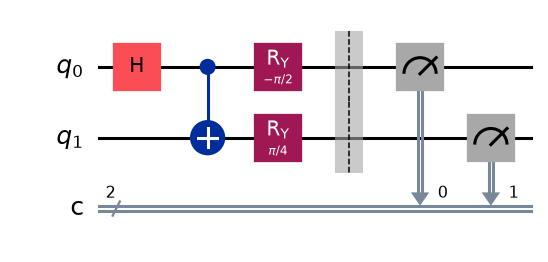

In [9]:
angulos_chsh = {
    "a,b": (0.0, np.pi/4),
    "a,b'": (0.0, -np.pi/4),
    "a',b": (np.pi/2, np.pi/4),
    "a',b'": (np.pi/2, -np.pi/4),
}

circuitos_chsh = {}
for par, (theta_a, theta_b) in angulos_chsh.items():
    qc = QuantumCircuit(2, 2)
    qc.h(0)
    qc.cx(0, 1)
    qc.ry(-theta_a, 0)
    qc.ry(-theta_b, 1)
    qc.barrier()
    qc.measure([0, 1], [0, 1])
    circuitos_chsh["CHSH " + par] = qc

circuitos_chsh["CHSH a',b'"].draw(output="mpl", plot_barriers=True)

In [10]:
def correlacion(resultado):
    total = sum(resultado.values())
    iguales = resultado.get("00", 0) + resultado.get("11", 0)
    return (iguales - (total - iguales))/total, total


def chsh(conteos_chsh):
    E = {}
    varianza = 0.0
    for par in angulos_chsh:
        E[par], total = correlacion(conteos_chsh["CHSH " + par])
        varianza = varianza + (1 - E[par]**2)/total
    S = E["a,b"] + E["a,b'"] + E["a',b"] - E["a',b'"]
    return S, np.sqrt(varianza), E


for nombre, circuito in circuitos_chsh.items():
    conteos[nombre] = medir(circuito, semilla)
    semilla = semilla + 1

S_ideal, error_ideal, E_ideal = chsh(conteos)
print("Simulador ideal:", ", ".join(f"E({par}) = {valor:+.3f}" for par, valor in E_ideal.items()))
print(f"S = {S_ideal:.3f} ± {error_ideal:.3f}   (2*sqrt(2) = {2*np.sqrt(2):.3f})")

Simulador ideal: E(a,b) = +0.710, E(a,b') = +0.670, E(a',b) = +0.734, E(a',b') = -0.724
S = 2.838 ± 0.045   (2*sqrt(2) = 2.828)


## 3.3 Equipo real contra simulador

In [11]:
previstos = {"Bell": ["00", "11"], "GHZ": ["000", "111"], "GHZ + X(1)": ["010", "101"]}


def fuera_de_lo_previsto(resultado, permitidos):
    total = sum(resultado.values())
    fuera = 0
    for clave, valor in resultado.items():
        if clave not in permitidos:
            fuera = fuera + valor
    return 100*fuera/total


fuentes = {"Simulador ideal": conteos, "Simulador con ruido": ibm["conteos_ruido"], "Equipo real": ibm["conteos_equipo"]}
tabla = pd.DataFrame({fuente: [fuera_de_lo_previsto(datos[nombre], previstos[nombre]) for nombre in previstos]
                      for fuente, datos in fuentes.items()}, index=list(previstos))
print("Disparos con un resultado que el estado ideal no permite (%):")
print(tabla.round(1).to_string())

valores_S = {}
for fuente, datos in fuentes.items():
    valores_S[fuente] = chsh(datos)
print("\nCHSH:")
for fuente, (S, error, E) in valores_S.items():
    print(f"  {fuente:<20} S = {S:.3f} ± {error:.3f}   (S - 2)/sigma_S = {(S - 2)/error:+.1f}")

Disparos con un resultado que el estado ideal no permite (%):
            Simulador ideal  Simulador con ruido  Equipo real
Bell                    0.0                  0.8          5.2
GHZ                     0.0                  1.6          6.3
GHZ + X(1)              0.0                  3.2          5.9

CHSH:
  Simulador ideal      S = 2.838 ± 0.045   (S - 2)/sigma_S = +18.8
  Simulador con ruido  S = 2.788 ± 0.045   (S - 2)/sigma_S = +17.4
  Equipo real          S = 2.568 ± 0.048   (S - 2)/sigma_S = +11.7


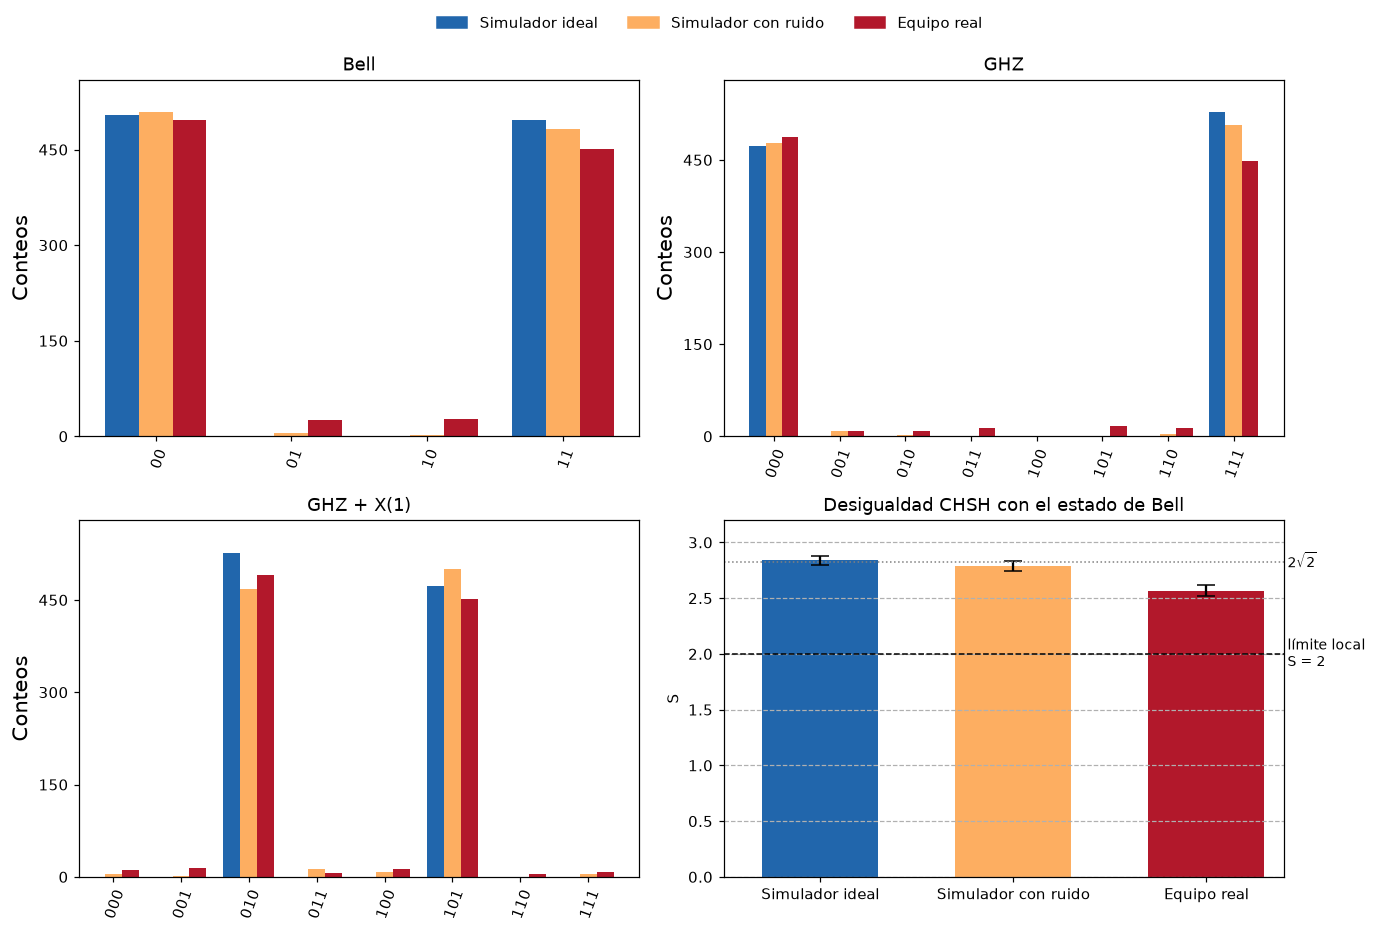

In [12]:
colores = ["#2166ac", "#fdae61", "#b2182b"]
fig, ejes = plt.subplots(2, 2, figsize=(13, 8.5))
for eje, nombre in zip([ejes[0, 0], ejes[0, 1], ejes[1, 0]], previstos):
    plot_histogram([fuente[nombre] for fuente in fuentes.values()], ax=eje, color=colores, bar_labels=False)
    eje.grid(False)
    eje.set_ylabel("Conteos")
    eje.set_title(nombre)

eje = ejes[1, 1]
posiciones = np.arange(len(valores_S))
eje.bar(posiciones, [valor[0] for valor in valores_S.values()], yerr=[valor[1] for valor in valores_S.values()],
        color=colores, capsize=6, width=0.6)
eje.axhline(2, color="black", lw=1, ls="--")
eje.text(2.42, 2, "límite local\nS = 2", fontsize=9, va="center")
eje.axhline(2*np.sqrt(2), color="gray", lw=1, ls=":")
eje.text(2.42, 2*np.sqrt(2), r"$2\sqrt{2}$", fontsize=9, va="center")
eje.set_xlim(-0.5, 2.4)
eje.set_xticks(posiciones)
eje.set_xticklabels(list(valores_S))
eje.set_ylim(0, 3.2)
eje.set_ylabel("S")
eje.set_title("Desigualdad CHSH con el estado de Bell")

parches = [plt.Rectangle((0, 0), 1, 1, color=color) for color in colores]
fig.legend(parches, list(fuentes), loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 0.97, 0.96))
plt.show()

En el equipo real, el 5 % de los disparos del estado de Bell y cerca del 6 % de los de tres qubits dan resultados que no deberían salir. Es el ruido del equipo: las compuertas no son perfectas, los qubits pierden su estado con el tiempo y la lectura a veces se equivoca. El simulador con el ruido que IBM reporta da menos (entre 0,8 % y 3,2 %), porque usa promedios de la última calibración del equipo y deja por fuera otros efectos.

En los tres circuitos sale un poco menos el resultado con más unos: 451 contra 497 en Bell, 449 contra 488 en GHZ y 451 contra 490 con la X. Es lo esperable, porque un qubit en $\ket1$ puede caer a $\ket0$ antes de leerse, pero uno en $\ket0$ no sube solo a $\ket1$. Cada diferencia por separado es pequeña (1,3 a 1,5 $\sigma$), pero se repite en los tres.

Aun con ese ruido, el equipo da $S=2{,}57\pm0{,}05$, muy por encima del límite clásico de 2 (11,7 $\sigma$): los qubits sí quedaron entrelazados. No llega a $2\sqrt2$ porque el ruido debilita las correlaciones. Un estado de Bell mezclado con ruido al azar,

$$\rho=v\,\ket{\Phi^+}\bra{\Phi^+}+(1-v)\,\frac{I}{4},$$

da $S=2\sqrt2\,v$, de donde $v\approx0{,}91$.

## 3.4 Uso del equipo y tiempos

IBM registra cuánto esperó el trabajo en la fila y cuánto tiempo usó el procesador. La celda lo compara con lo que tarda
el simulador en este computador con los mismos siete circuitos, y mide cuánto tarda el simulador a medida que crece el
número de qubits.

Espera en la fila de IBM        310.800
Procesamiento en IBM             62.600
Uso del procesador cuántico       4.000
Simulador en este computador      0.698

Plan gratuito: 4 s de 600 s (0.67 %)


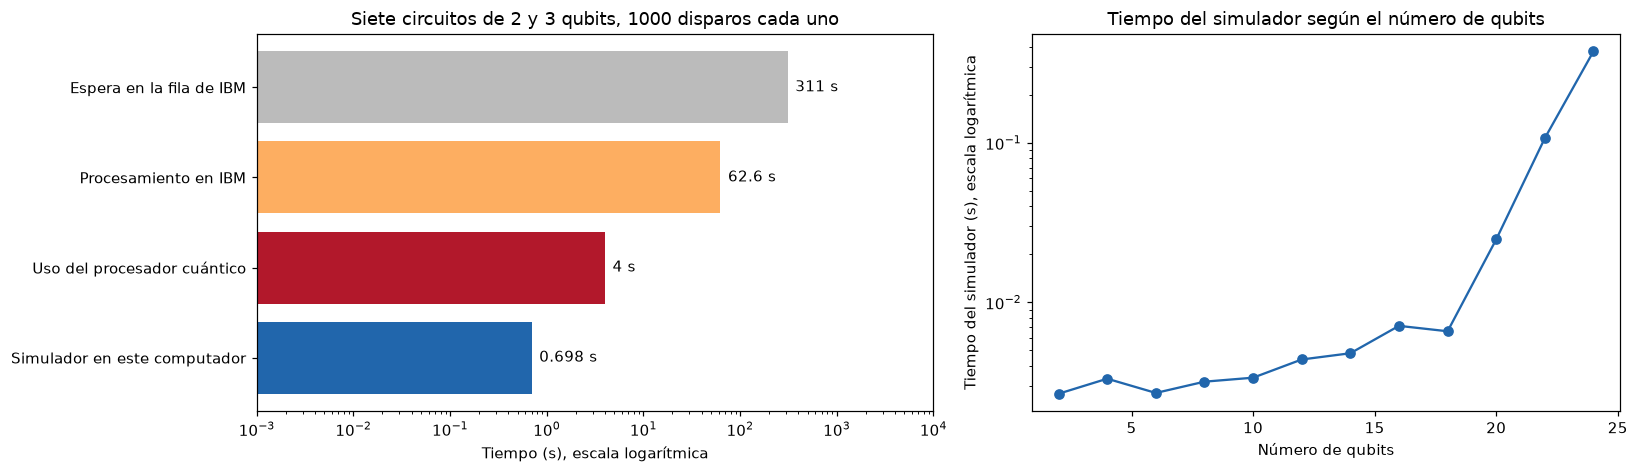

In [13]:
uso = ibm["uso"]

inicio = time.perf_counter()
semilla_tiempo = 2026
for circuito in list(circuitos.values()) + list(circuitos_chsh.values()):
    medir(circuito, semilla_tiempo)
    semilla_tiempo = semilla_tiempo + 1
t_simulador = time.perf_counter() - inicio

tiempos = pd.Series({
    "Espera en la fila de IBM": uso["cola_s"],
    "Procesamiento en IBM": uso["en_ejecucion_s"],
    "Uso del procesador cuántico": uso["equipo_s"],
    "Simulador en este computador": t_simulador,
}, name="segundos")
print(tiempos.round(3).to_string())
print(f"\nPlan gratuito: {uso['equipo_s']} s de {uso['limite_s']} s ({100*uso['equipo_s']/uso['limite_s']:.2f} %)")

simulador_vector = AerSimulator(method="statevector")
numeros_qubits = list(range(2, 25, 2))
segundos = []
for n in numeros_qubits:
    qc = QuantumCircuit(n, n)
    qc.h(0)
    for i in range(n - 1):
        qc.cx(i, i + 1)
    qc.measure(list(range(n)), list(range(n)))
    compilado = transpile(qc, simulador_vector)
    inicio = time.perf_counter()
    simulador_vector.run(compilado, shots=disparos, seed_simulator=2026).result()
    segundos.append(time.perf_counter() - inicio)

fig, ejes = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
ejes[0].barh(list(tiempos.index), tiempos.values, color=["#bbbbbb", "#fdae61", "#b2182b", "#2166ac"])
ejes[0].set_xscale("log")
ejes[0].set_xlim(1e-3, 1e4)
for y, valor in enumerate(tiempos.values):
    ejes[0].text(valor*1.2, y, f"{valor:.3g} s", va="center")
ejes[0].invert_yaxis()
ejes[0].set_xlabel("Tiempo (s), escala logarítmica")
ejes[0].set_title("Siete circuitos de 2 y 3 qubits, 1000 disparos cada uno")

ejes[1].semilogy(numeros_qubits, segundos, "o-", color="#2166ac")
ejes[1].set_xlabel("Número de qubits")
ejes[1].set_ylabel("Tiempo del simulador (s), escala logarítmica")
ejes[1].set_title("Tiempo del simulador según el número de qubits")
plt.tight_layout()
plt.show()

El trabajo esperó 5 min 11 s en la fila de IBM, tardó 1 min en procesarse y usó 4 s del procesador cuántico, el 0,67 % de los 10 minutos gratuitos. Los tiempos salen del registro que IBM guarda del trabajo `dbt8753eq3sc73evga6g`, y el límite de 10 minutos, de los [planes de IBM](https://quantum.cloud.ibm.com/docs/guides/plans-overview).

**Resultado del extra.**

1. **Entrelazamiento real:** comprobado. $S=2{,}57\pm0{,}05$, por encima del límite clásico de 2.
2. **Ruido:** entre 5 % y 6 % de resultados que no deberían salir; el simulador perfecto da 0 %.
3. **Compuertas del equipo:** los circuitos se traducen a $R_Z$, $\sqrt X$ y CZ y hacen lo mismo que los del punto 2.
4. **Tiempo:** con tan pocos qubits el simulador de este computador es más rápido. Pero desde unos 16 qubits cada qubit de más duplica el tiempo del simulador (segunda gráfica), así que con los 156 qubits del equipo no se podría simular: ahí es donde el equipo real vale la pena.

---

## Referencias

- Enunciado: [`Laboratorios/Lab_9_QC.ipynb`](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Laboratorios/Lab_9_QC.ipynb).
- Material del curso: [`Sesiones/QC/3_two_level_system.ipynb`](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Sesiones/QC/3_two_level_system.ipynb),
  [`Sesiones/QC/4_logic_gates_in_QC.ipynb`](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Sesiones/QC/4_logic_gates_in_QC.ipynb) y
  [`Sesiones/QC/5_qiskit.ipynb`](https://github.com/anferivera/Fisica_Computacional_1/blob/main/Sesiones/QC/5_qiskit.ipynb).
- K. Likharev, *Essential Graduate Physics, Quantum Mechanics*, sección 5.1, [Two-level systems](https://phys.libretexts.org/Bookshelves/Quantum_Mechanics/Essential_Graduate_Physics_-_Quantum_Mechanics_(Likharev)/05%3A_Some_Exactly_Solvable_Problems/5.01%3A_Two-level_Systems).
- C. Cohen-Tannoudji, B. Diu y F. Laloë, *Quantum Mechanics*, vol. 1, Wiley (1977), pp. 406-414.
- R. P. Feynman, R. B. Leighton y M. Sands, *The Feynman Lectures on Physics*, vol. III, cap. 9, [The ammonia maser](https://www.feynmanlectures.caltech.edu/III_09.html).
- M. A. Nielsen e I. L. Chuang, *Quantum Computation and Quantum Information*, Cambridge (2010), secciones 1.3.6 y 2.6.
- J. F. Clauser, M. A. Horne, A. Shimony y R. A. Holt, Proposed experiment to test local hidden-variable theories,
  *Phys. Rev. Lett.* **23**, 880 (1969).
- IBM Quantum, [planes de acceso](https://quantum.cloud.ibm.com/docs/guides/plans-overview) y
  [Qiskit Runtime](https://quantum.cloud.ibm.com/docs/guides/primitives).